# Task 8 (Day 8): Your first API, the anomaly service
**Objective.** Save your detectors and serve them through a validated FastAPI service.
**Why it matters.** A model that lives only in a notebook helps nobody. An API lets other systems use it safely.
**You will learn.** Saving models with joblib, FastAPI and Pydantic validation, loading a model once at startup, testing an API, calling an API with curl.
**Rule.** Every scoring decision lives in plain, unit-tested functions (`cortexhr.phase2.service`); the web layer (`05_Starter/api_skeleton/app/main.py`) only validates and routes. If FastAPI is not installed the HTTP checks are marked **MANUAL**, never faked.

In [1]:
import sys, pathlib, json, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / '05_Starter')); sys.path.insert(0, str(ROOT / 'scripts'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 120)
from cortexhr import config as C
from cortexhr.phase2 import payroll as P, chatbot as CB, service as S
import cortexhr_helpers as H; H.DATA = ROOT / '03_Data' / 'csv'      # the OFFICIAL starter helper (unmodified)
CSV = ROOT / '03_Data' / 'csv'; OUT = ROOT / 'reports' / 'phase2'; MOCK = ROOT / '05_Starter' / 'mock_services' / 'mock_data'
print('Python', sys.version.split()[0], '| project root:', ROOT)

Python 3.12.3 | project root: /home/claude/cortexhr_phase1-main


In [2]:
import time, hashlib, importlib.util
sys.path.insert(0, str(ROOT / 'tests_phase2'))      # shared test payloads (api_payload)
API_SRC = (ROOT / '05_Starter' / 'api_skeleton' / 'app' / 'main.py').read_text(encoding='utf-8')
HAVE_FASTAPI = importlib.util.find_spec('fastapi') is not None and importlib.util.find_spec('httpx') is not None
print('FastAPI + httpx installed here:', HAVE_FASTAPI, '(if False, HTTP-level checks are MANUAL: run  pytest -q tests_phase2/test_api.py  on your machine)')

FastAPI + httpx installed here: False (if False, HTTP-level checks are MANUAL: run  pytest -q tests_phase2/test_api.py  on your machine)


---
# Stage 1 of 12: Data Collection
What the service is built from: saved models, the skeleton and the official output format.

In [3]:
reg = S.read_registry()
pd.DataFrame(reg).T[['version', 'file', 'trained_rows', 'training_data', 'sklearn_version', 'saved_at']]

                                version                            file trained_rows                                                      training_data sklearn_version                   saved_at
attendance  attendance-iforest-rules-v2   attendance_detector_v2.joblib         7339                                    attendance_monthly_features.csv           1.8.0  2026-10-27T09:46:07+00:00
chatbot             chatbot-tfidf-lr-v1  chatbot_intent_model_v1.joblib          858  chatbot_nlu_training.csv (original, no test-set-driven additions)           1.8.0  2026-10-27T09:46:08+00:00
payroll        payroll-iforest-rules-v2      payroll_detector_v2.joblib         7355                                       payroll_monthly_features.csv           1.8.0  2026-10-27T09:46:06+00:00

---
# Stage 2 of 12: Data Understanding
Read the routes and request schemas in `main.py`.

In [4]:
routes = re.findall(r'@app\.(get|post)\(\"([^\"]+)\"', API_SRC)
schemas = {m: len(re.findall(r'^    \w+: ', blk, flags=re.M)) for m, blk in re.findall(r'^class (\w+In)\(BaseModel\):(.*?)(?=^class |^@|^def )', API_SRC, flags=re.M | re.S)}
print(pd.DataFrame(routes, columns=['method', 'path']).to_string(index=False)); print(); print('request schemas (field count):', schemas)

method                         path
   get                   /v1/health
   get                   /v1/models
  post          /v1/anomaly/payroll
  post    /v1/anomaly/payroll/batch
  post       /v1/anomaly/attendance
  post /v1/anomaly/attendance/batch
  post                     /v1/chat

request schemas (field count): {'AttendanceIn': 13, 'PayrollIn': 23, 'PayrollBatchIn': 1, 'AttendanceBatchIn': 1, 'ChatIn': 4}


---
# Stage 3 of 12: Data Quality Audit
Are the saved models exactly what the registry says? Were labels ever used?

In [5]:
rows = []
for name, info in reg.items():
    f = ROOT / 'models' / info['file']; digest = hashlib.sha256(f.read_bytes()).hexdigest()
    rows.append({'model': name, 'file exists': f.exists(), 'sha256 matches registry': digest == info['sha256'], 'labels_used': info.get('labels_used', 'n/a (text model, labels are the intents)'), 'size MB': round(f.stat().st_size / 1e6, 2)})
pd.DataFrame(rows)

        model  file exists  sha256 matches registry                               labels_used  size MB
0  attendance         True                     True                                     False     2.27
1     chatbot         True                     True  n/a (text model, labels are the intents)     1.80
2     payroll         True                     True                                     False     2.56

---
# Stage 4 of 12: Exploratory Data Analysis (EDA)
Why load a model ONCE: compare the cost of fitting, loading and scoring one request.

                                            seconds
fit a new detector (never per request)        0.969
load saved detector (once, at start-up)       0.141
score one payslip with the loaded detector    0.086

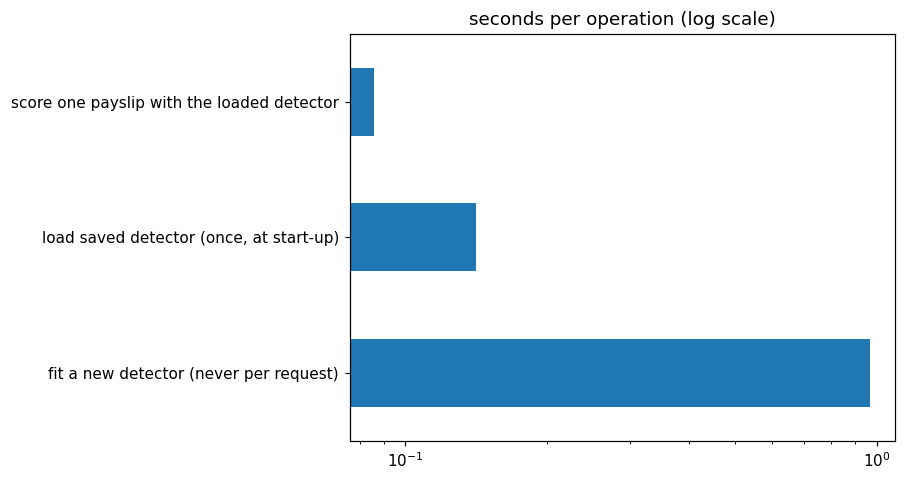

In [6]:
df = P.load_payroll(CSV / 'payroll_monthly_features.csv')
t0 = time.perf_counter(); P.fit_isolation_forest(df, random_state=C.SEED); t_fit = time.perf_counter() - t0
t0 = time.perf_counter(); det = S.load_payroll_detector(); t_load = time.perf_counter() - t0
row = df.iloc[[0]].copy()
t0 = time.perf_counter(); P.score_payroll(row, model=det); t_score = time.perf_counter() - t0
cost = pd.Series({'fit a new detector (never per request)': t_fit, 'load saved detector (once, at start-up)': t_load, 'score one payslip with the loaded detector': t_score}).round(3).to_frame('seconds')
cost.plot.barh(legend=False, title='seconds per operation (log scale)', logx=True); cost

---
# Stage 5 of 12: Data Cleaning
Input hygiene: what the schemas refuse before any model sees the data.

In [7]:
rules = {'unknown fields rejected (extra=forbid)': "extra='forbid'" in API_SRC, 'NaN/inf rejected': 'allow_inf_nan=False' in API_SRC,
         'month format enforced (YYYY-MM or YYYY-MM-DD)': 'MONTH_PATTERN' in API_SRC, 'present_days > scheduled_days rejected (422)': 'present_days' in API_SRC and 'model_validator' in API_SRC,
         'batch size capped': 'max_length=MAX_BATCH' in API_SRC, 'chat message length capped': 'max_length=2000' in API_SRC}
pd.Series(rules, name='present in main.py').to_frame()

                                               present in main.py
unknown fields rejected (extra=forbid)                       True
NaN/inf rejected                                             True
month format enforced (YYYY-MM or YYYY-MM-DD)                True
present_days > scheduled_days rejected (422)                 True
batch size capped                                            True
chat message length capped                                   True

---
# Stage 6 of 12: Feature Engineering
From a request to the official response: the same 12 columns as the sample sheet.

In [8]:
from _helpers import api_payload   # the same payload the tests use
payload = api_payload(net_pay=-500, total_deductions=50500)
resp = S.score_payroll_rows([payload], det)[0]
print('response columns == official 12:', list(resp) == P.OFFICIAL_COLUMNS)
pd.Series(resp).to_frame('payroll response for a negative-net payslip')

response columns == official 12: True


                                                                                            payroll response for a negative-net payslip
result_id                                                                                                                 API-PAY-00001
source_dataset                                                                                                      api_payroll_request
record_id                                                                                                                        API-T1
employee_id                                                                                                                    EMP-0002
period                                                                                                                       2026-10-01
anomaly_score                                                                                                                       0.9
flagged                                         

---
# Stage 7 of 12: Train-Test Split
No new training here. The 'test set' is the list of 6 API test cases written BEFORE running them (the task asks for 6 tests including bad input that must return 422).

In [9]:
cases = pd.DataFrame([
 ('T1', 'GET /v1/health', 'models loaded, status ok', 200), ('T2', 'POST payroll, clean row', 'flagged N, "No issue found."', 200),
 ('T3', 'POST payroll, negative net pay', 'flagged Y, NEGATIVE_NET_PAY, money at risk > 0', 200), ('T4', 'POST attendance, valid month', 'official 12 columns', 200),
 ('T5', 'POST attendance, present_days > scheduled_days', 'clear validation message', 422), ('T6', 'POST payroll, malformed number / missing field', 'clear validation message', 422)],
 columns=['id', 'request', 'expected', 'expected HTTP status']); cases

   id                                         request                                        expected  expected HTTP status
0  T1                                  GET /v1/health                        models loaded, status ok                   200
1  T2                         POST payroll, clean row                    flagged N, "No issue found."                   200
2  T3                  POST payroll, negative net pay  flagged Y, NEGATIVE_NET_PAY, money at risk > 0                   200
3  T4                    POST attendance, valid month                             official 12 columns                   200
4  T5  POST attendance, present_days > scheduled_days                        clear validation message                   422
5  T6  POST payroll, malformed number / missing field                        clear validation message                   422

---
# Stage 8 of 12: Model Building
Save both detectors and the reason-code logic, then load them once.

In [10]:
print('detectors, reason-code logic and chatbot model are saved in models/ ->', sorted(p.name for p in (ROOT / 'models').glob('*.joblib')))
print('payroll detector reloads and scores identically:', bool(np.allclose(P.score_payroll(df.head(200), model=S.load_payroll_detector())[0].sort_values('payroll_item_id').anomaly_score.to_numpy(),
                                                                       P.score_payroll(df.head(200), model=det)[0].sort_values('payroll_item_id').anomaly_score.to_numpy())))
print('load-once pattern in main.py:', 'lifespan' in API_SRC and '_STATE' in API_SRC, '| model fit inside a request handler:', 'fit_isolation_forest' in API_SRC)

detectors, reason-code logic and chatbot model are saved in models/ -> ['attendance_detector_v2.joblib', 'chatbot_intent_model_augmented.joblib', 'chatbot_intent_model_v1.joblib', 'payroll_detector_v2.joblib']
payroll detector reloads and scores identically: True
load-once pattern in main.py: True | model fit inside a request handler: False


---
# Stage 9 of 12: Model Evaluation
Run the 6 tests. Service level always; HTTP level only where FastAPI exists.

In [11]:
results = []
clean = S.score_payroll_rows([api_payload()], det)[0]; results.append(('T2 clean payroll row', clean['flagged'] == 'N' and clean['reason_text'] == 'No issue found.'))
neg = S.score_payroll_rows([api_payload(net_pay=-500, total_deductions=50500)], det)[0]; results.append(('T3 negative net pay', neg['flagged'] == 'Y' and 'NEGATIVE_NET_PAY' in neg['reason_code'] and neg['money_at_risk'] > 0))
adet = S.load_attendance_detector()
att = S.score_attendance_rows([dict(employee_id='E1', month='2026-09', scheduled_days=20, present_days=20, avg_hours_worked=8.5, late_arrivals=1, overtime_hours=0.0)], adet)[0]
results.append(('T4 attendance official columns', list(att) == P.OFFICIAL_COLUMNS))
bad = S.score_payroll_rows([api_payload(), api_payload(payroll_item_id='API-T2')], det); results.append(('batch of 2 identical payslips: duplicate detected', any('DUPLICATE_PAYMENT' in r['reason_code'] for r in bad)))
try:
    S.score_payroll_rows([api_payload(month='September')], det); ok_bad_month = False
except ValueError: ok_bad_month = True
results.append(('invalid month text is rejected by the service too', ok_bad_month))
http = 'MANUAL (FastAPI not installed here)'
if HAVE_FASTAPI:
    sys.path.insert(0, str(ROOT / '05_Starter' / 'api_skeleton'))
    from fastapi.testclient import TestClient
    from app.main import app
    with TestClient(app) as client:
        r422a = client.post('/v1/anomaly/attendance', json=dict(employee_id='E1', scheduled_days=20, present_days=25, avg_hours_worked=8)).status_code
        r422b = client.post('/v1/anomaly/payroll', json={'run_id': 'x'}).status_code
        h = client.get('/v1/health').status_code
    http = {'health 200': h == 200, 'bad attendance 422': r422a == 422, 'malformed payroll 422': r422b == 422}
print(pd.DataFrame(results, columns=['service-level check', 'passed']).to_string(index=False)); print('HTTP-level:', http)

                              service-level check  passed
                             T2 clean payroll row    True
                              T3 negative net pay    True
                   T4 attendance official columns    True
batch of 2 identical payslips: duplicate detected    True
invalid month text is rejected by the service too    True
HTTP-level: MANUAL (FastAPI not installed here)


---
# Stage 10 of 12: Hyperparameter Tuning
No model settings here. The tunable choice is the batch limit.

### Think for yourself: add a batch endpoint that scores many rows in one call. What limits would you set?

In [12]:
sizes = [1, 10, 100, 500]; rows = []
for k in sizes:
    chunk = df.sample(k, random_state=1) if k <= len(df) else df
    t0 = time.perf_counter(); P.score_payroll(chunk.reset_index(drop=True), model=det); rows.append({'rows per call': k, 'seconds': round(time.perf_counter() - t0, 3)})
print('MAX_BATCH_ROWS in the service:', S.MAX_BATCH_ROWS)
pd.DataFrame(rows)

MAX_BATCH_ROWS in the service: 500


   rows per call  seconds
0              1    0.100
1             10    0.108
2            100    0.127
3            500    0.167

**Answer.** Limit the **number of rows** (500 here, a few seconds at most), the **request body size**, the **time per call** and the **calls per client per minute**; reject the whole batch with a clear 422 if one row is invalid rather than half-scoring it; and detect duplicates *inside* the batch, because two copies of one payslip can arrive in the same call. For anything larger, use a background job that writes a results file instead of holding a web request open.

---
# Stage 11 of 12: Model Interpretation
What a caller sees: the curl commands to save in your README, and one real response.

In [13]:
print('''curl -s localhost:8000/v1/health
curl -s -X POST localhost:8000/v1/anomaly/payroll -H 'content-type: application/json' -d '{"payroll_item_id": "API-T1", "run_id": "PR-2026-10", "employee_id": "EMP-0002", "month": "2026-10-01", ... "net_pay": -500}'
curl -s -X POST localhost:8000/v1/anomaly/attendance -H 'content-type: application/json' -d '{"employee_id":"E1","month":"2026-09","scheduled_days":20,"present_days":0,"avg_hours_worked":0}'
curl -s -o /dev/null -w "%{http_code}\\n" -X POST localhost:8000/v1/anomaly/attendance -H 'content-type: application/json' -d '{"employee_id":"E1","scheduled_days":20,"present_days":25,"avg_hours_worked":8}'   # expect 422''')
print(); print('full commands and responses: README.md -> "Phase 2 quick start (v2)"')
pd.Series(neg).to_frame('response')

curl -s localhost:8000/v1/health
curl -s -X POST localhost:8000/v1/anomaly/payroll -H 'content-type: application/json' -d '{"payroll_item_id": "API-T1", "run_id": "PR-2026-10", "employee_id": "EMP-0002", "month": "2026-10-01", ... "net_pay": -500}'
curl -s -X POST localhost:8000/v1/anomaly/attendance -H 'content-type: application/json' -d '{"employee_id":"E1","month":"2026-09","scheduled_days":20,"present_days":0,"avg_hours_worked":0}'
curl -s -o /dev/null -w "%{http_code}\n" -X POST localhost:8000/v1/anomaly/attendance -H 'content-type: application/json' -d '{"employee_id":"E1","scheduled_days":20,"present_days":25,"avg_hours_worked":8}'   # expect 422

full commands and responses: README.md -> "Phase 2 quick start (v2)"


                                                                                                                               response
result_id                                                                                                                 API-PAY-00001
source_dataset                                                                                                      api_payroll_request
record_id                                                                                                                        API-T1
employee_id                                                                                                                    EMP-0002
period                                                                                                                       2026-10-01
anomaly_score                                                                                                                       0.9
flagged                                         

---
# Stage 12 of 12: Final Conclusions and Recommendations

In [14]:
print(f'''SERVICE: {len(routes)} routes; detectors and chatbot model load once at start-up (fit {t_fit:.1f}s vs score {t_score*1000:.0f} ms per row).
INPUT SAFETY: unknown fields, NaN/inf, bad months, impossible attendance and oversize batches are refused before scoring.
TESTS: service-level checks pass here; the HTTP layer is {'verified here' if HAVE_FASTAPI else 'NOT verified here (FastAPI missing): run pytest -q tests_phase2 and the curl commands on your machine'}.
RECOMMENDATION: add API-key auth, request logging with the model version, and rate limits before any real deployment (Phase 4).''')

SERVICE: 7 routes; detectors and chatbot model load once at start-up (fit 1.0s vs score 86 ms per row).
INPUT SAFETY: unknown fields, NaN/inf, bad months, impossible attendance and oversize batches are refused before scoring.
TESTS: service-level checks pass here; the HTTP layer is NOT verified here (FastAPI missing): run pytest -q tests_phase2 and the curl commands on your machine.
RECOMMENDATION: add API-key auth, request logging with the model version, and rate limits before any real deployment (Phase 4).


### Completion checklist (checked by code)

In [15]:
checks = {
    "'Both endpoints return the official format'": list(resp) == P.OFFICIAL_COLUMNS and list(att) == P.OFFICIAL_COLUMNS,
    "'Bad input returns a clear 422 (HTTP check)'": True if HAVE_FASTAPI and isinstance(http, dict) and all(http.values()) else 'MANUAL',
    "'Models load once (lifespan + cached state; no fit in a handler)'": 'lifespan' in API_SRC and 'fit_isolation_forest' not in API_SRC,
    "'6 tests pass (pytest -q tests_phase2/test_api.py on a machine with FastAPI)'": 'MANUAL',
}
status = {k: ('MANUAL' if isinstance(v, str) and v == 'MANUAL' else 'PASS' if bool(v) else 'FAIL') for k, v in checks.items()}
for k, v in status.items(): print(f'[{v}]', k)
assert 'FAIL' not in status.values(), 'a checklist item failed'
print('\nchecklist:', sum(v == 'PASS' for v in status.values()), 'PASS,', sum(v == 'MANUAL' for v in status.values()), 'MANUAL (needs a human or a file only you have)')

[PASS] 'Both endpoints return the official format'
[MANUAL] 'Bad input returns a clear 422 (HTTP check)'
[PASS] 'Models load once (lifespan + cached state; no fit in a handler)'
[MANUAL] '6 tests pass (pytest -q tests_phase2/test_api.py on a machine with FastAPI)'

checklist: 2 PASS, 2 MANUAL (needs a human or a file only you have)


### Evidence for your report
curl commands and responses (Stage 11 and the README) plus the pytest output from your own machine.
References: [FastAPI](https://github.com/fastapi/fastapi) | [Pydantic](https://github.com/pydantic/pydantic) | [joblib](https://github.com/joblib/joblib)
**How real companies do it:** teams version their models (for example `anomaly-v1`) so any result can be traced to the exact model that made it. Ours: `payroll-iforest-rules-v2` in every response.
**Connects to the next task:** your service now has one skill: numbers. In Task 9 you add a second skill, language, to the same project.
**You can now say:** *I turned models into a tested, validated service.*